<a href="https://colab.research.google.com/github/Nora0613/website/blob/main/Kopie_von_BCI_and_Law_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Research question and hypothesis

Dataset and ethics

Python setup

In [1]:
%pip install -q mne numpy pandas matplotlib scikit-learn

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.1 which is incompatible.


In [6]:
import mne
print ("MNE installed successfully!")
print ("Version:", mne.__version__)

MNE installed successfully!
Version: 1.13.2


In [ ]:
import numpy as np
import mne
import sklearn

from sklearn.metrics import balanced_accuracy_score

print("NumPy:", np.__version__)
print("MNE:", mne.__version__)
print("Scikit-learn:", sklearn.__version__)
print("All essential imports work!")

NumPy: 2.1.3
MNE: 1.13.2
Scikit-learn: 1.6.1
All essential imports work!


In [ ]:
%pip install --upgrade --force-reinstall scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 18.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 49.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 40.2 MB/s  0:00:00
  Attempting uninstall: threadpoolctl
    Found existing installation: threadpoolctl 3.7.0
    Uninstalling threadpoolctl-3.7.0:
      Successfully uninstalled threadpoolctl-3.7.0
  Attempting uninstall: numpy
    Found existing installation: numpy 2.1.3
    Uninstalling numpy-2.1.3:
      Successfully uninstalled numpy-2.1.3
  Attempting uninstall: narwhals
    Found existing installation: narwhals 2.27.1
    Uninstalling narwhals-2.27.1:
      Successfully uninstalled narwhals-2.27.1
  Attempting uninstall: cloudpickle
    Found existing installation: cloudpickle 3.1.2
    Uninstalling cloudpickle-3.1.2:
      Successfully uninstalled cloudpickle-3.1.2
  Attempting uninstall: scipy
    Found existing installation: scipy 1.16.3
    Uninstalling scipy-1.16.3:
    

In [ ]:
import sklearn
from sklearn.metrics import balanced_accuracy_score

print("scikit-learn version:", sklearn.__version__)
print("Import successful!")

scikit-learn version: 1.6.1
Import successful!


In [7]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)


print ("MNE version:", mne.__version__)
print("Python environment is ready")

MNE version: 1.13.2
Python environment is ready


In [3]:
import os
import mne
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt



In [4]:
from mne.datasets import eegbci

files = eegbci.load_data(
    subjects=[1],
    runs=[4, 8, 12],
    path="/content/mne_data"
)

print("Files downloaded or located:")

for file in files:
  print(os.path.basename(file))
  print(file)

Do you want to set the path:
    /content/mne_data
as the default EEGBCI dataset path in the mne-python config [y]/n? y
Attempting to create new mne-python configuration file:
/root/.mne/mne-python.json
Could not read the /root/.mne/mne-python.json json file during the writing. Assuming it is empty. Got: Expecting value: line 1 column 1 (char 0)
Download complete in 05m10s (7.4 MB)
Files downloaded or located:
S001R04.edf
/content/mne_data/MNE-eegbci-data/files/eegmmidb/1.0.0/S001/S001R04.edf
S001R08.edf
/content/mne_data/MNE-eegbci-data/files/eegmmidb/1.0.0/S001/S001R08.edf
S001R12.edf
/content/mne_data/MNE-eegbci-data/files/eegmmidb/1.0.0/S001/S001R12.edf


In [8]:
raw = mne.io.read_raw_edf(
    files[0],
    preload=True,
    verbose=False
)

mne.datasets.eegbci.standardize(raw)

print(raw)
print("\nSampling frequency:", raw.info["sfreq"], "Hz")
print("Number of channels:", len(raw.ch_names))
print("First 15 channel names:", raw.ch_names[:15])
print("\nAnnotations:")
print(raw.annotations)

<RawEDF | S001R04.edf, 64 x 20000 (125.0 s), ~9.8 MiB, data loaded>

Sampling frequency: 160.0 Hz
Number of channels: 64
First 15 channel names: ['FC5', 'FC3', 'FC1', 'FCz', 'FC2', 'FC4', 'FC6', 'C5', 'C3', 'C1', 'Cz', 'C2', 'C4', 'C6', 'CP5']

Annotations:
<Annotations | 30 segments: T0 (15), T1 (8), T2 (7)>


In [ ]:
events, event_id = mne.events_from_annotations(
    raw,
    verbose=False
)
print("Available event labels:")
print(event_id)

print("\nNumber of events:",len(events))

Available event labels:
{'T0': 1, 'T1': 2, 'T2': 3}

Number of events: 30


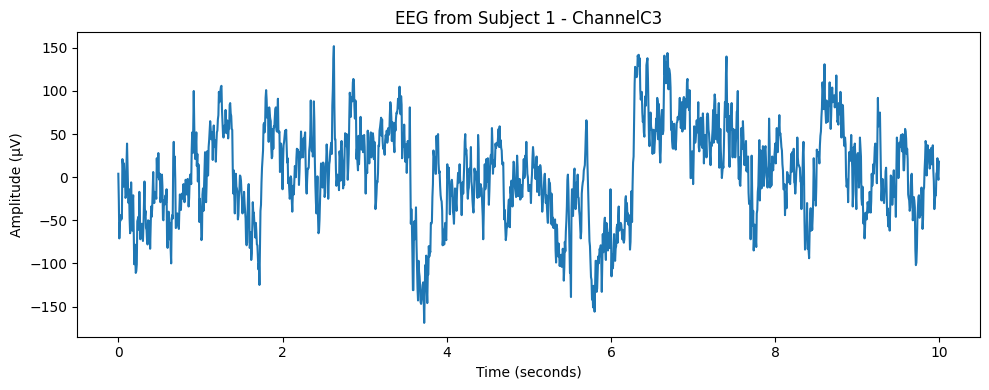

In [ ]:
channel = "C3" if "C3" in raw.ch_names else raw.ch_names[0]

signal, times = raw.get_data(
    picks=[channel],
    start=0,
    stop=1600,
    return_times=True
)

plt.figure(figsize=(10, 4))
plt.plot(times, signal[0]*1e6)
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (µV)")
plt.title(f"EEG from Subject 1 - Channel{channel}")
plt.tight_layout()
plt.show()

In [5]:
import numpy as np
import mne
from mne.datasets import eegbci

runs = [4, 8, 12]

files = eegbci.load_data(
    subjects=[1],
    runs=runs,
    path="/content/mne_data"

)

results = {}

for run, file in zip(runs, files):
  print(f"Processing run {run}...")

  raw = mne.io.read_raw_edf(
      file, preload=True, verbose=False
  )

  eegbci.standardize(raw)

  events, event_id = mne.events_from_annotations(
      raw, verbose=False
  )

  selected_events = {
      name: event_id[name]
      for name in ["T1", "T2"]
      if name in event_id
  }

  if len(selected_events) !=2:
    raise ValueError(
        f"Run {run} does not contain both T1 and T2 events"
    )

    epochs = mne.Epochs(
        raw,
        events,
        event_id=selected_events,
        tmin=0.5,
        tmax=2.5,
        baseline=None,
        picks="eeg",
        preload=True,
        verbose=False
    )

    X = epochs.get_data().reshape(len(epochs), -1)

    y = (
        epochs.events[:, -1] == selected_events["T2"]
    ).astype(int)

    results[run] = (X, y)

    print(f"Run {run}:{X.shape[0]} trials, {X.shape[1]} features")

    print("Results created:", list(results.keys()))

Do you want to set the path:
    /content/mne_data
as the default EEGBCI dataset path in the mne-python config [y]/n? y
Attempting to create new mne-python configuration file:
/root/.mne/mne-python.json
Could not read the /root/.mne/mne-python.json json file during the writing. Assuming it is empty. Got: Expecting value: line 1 column 1 (char 0)
Download complete in 09m28s (7.4 MB)
Processing run 4...
Processing run 8...
Processing run 12...


In [ ]:
print("results" in globals())

True


In [7]:
print("Stored runs:", list(results.keys()))
print("Number of entries:", len(results))

Stored runs: []
Number of entries: 0


In [27]:
import numpy as np
import mne
from mne.datasets import eegbci

runs = [4, 8, 12]


files = eegbci.load_data(
    subjects=[1],
    runs=runs,
    path="/content/mne_data"
)

print("Number of EEG files found:", len(files))

for file in files:
  print(file)

Number of EEG files found: 3
/content/mne_data/MNE-eegbci-data/files/eegmmidb/1.0.0/S001/S001R04.edf
/content/mne_data/MNE-eegbci-data/files/eegmmidb/1.0.0/S001/S001R08.edf
/content/mne_data/MNE-eegbci-data/files/eegmmidb/1.0.0/S001/S001R12.edf


In [10]:
raws = []

for file in files:
  raw = mne.io.read_raw_edf(
      file,
      preload=True,
      verbose=False
  )
  raws.append(raw)

  print("Number of EEG recordings loaded:", len(raws))

Number of EEG recordings loaded: 1
Number of EEG recordings loaded: 2
Number of EEG recordings loaded: 3


In [11]:
for i, raw in enumerate(raws):
  print(f"Run {runs[i]}")
  print("Sampling frequency:", raw.info["sfreq"], "Hz")
  print("Number of channels:", len(raw.ch_names))
  print("Channel names:", raw.ch_names[:10])
  print()

Run 4
Sampling frequency: 160.0 Hz
Number of channels: 64
Channel names: ['Fc5.', 'Fc3.', 'Fc1.', 'Fcz.', 'Fc2.', 'Fc4.', 'Fc6.', 'C5..', 'C3..', 'C1..']

Run 8
Sampling frequency: 160.0 Hz
Number of channels: 64
Channel names: ['Fc5.', 'Fc3.', 'Fc1.', 'Fcz.', 'Fc2.', 'Fc4.', 'Fc6.', 'C5..', 'C3..', 'C1..']

Run 12
Sampling frequency: 160.0 Hz
Number of channels: 64
Channel names: ['Fc5.', 'Fc3.', 'Fc1.', 'Fcz.', 'Fc2.', 'Fc4.', 'Fc6.', 'C5..', 'C3..', 'C1..']



In [19]:
import numpy as np
import mne
from mne.datasets import eegbci

results = {}
runs = [4, 8, 12]

files = eegbci.load_data(
    subjects=1,
    runs=runs
)

print("Number of files loaded:", len(files))

Number of files loaded: 3


In [29]:
results = {}

for run, raw in zip(runs, raws):
  print(f"Processing run {run}...")

  events, annotation_event_id = mne.events_from_annotations(
      raw,
      verbose=False
  )

print("Available event labels:", list(annotation_event_id.keys()))

if "T1" not in annotation_event_id or "T2" not in annotation_event_id:
  raise ValueError(
      f"Run {run} does not contain both T1 and T2 events."
  )

  selected_events = {
      "T1": annotation_event_id["T1"],
      "T2": annotation_event_id["T2"]
  }

  epochs = mne.Epochs(
      raw,
      events,
      event_id=selected_events,
      tmin=0.5,
      tmax=2.5,
      baseline=None,
      picks="eeg",
      preload=True,
      verbose=False
  )

  X = epochs.get_data().reshape(len(epochs), -1)

  y = (epochs.events[:, -1] == selected_events["T2"]).astype(int)

  results[run] = (X, y)

  print(f"Run {run}: {X.shape[0]} trials, {X.shape[1]}features")
  print(f"Left-hand trials: {(y == 0).sum()}")
  print(f"Right-hand trials: {(y == 1).sum()}")

  print("Results created:", list(results.keys()))


Processing run 4...
Processing run 8...
Processing run 12...
Available event labels: ['T0', 'T1', 'T2']


In [31]:
print("Results keys:", list(results.keys()))


for run, (X, y) in results.items():
  print(f"Run {run}: {X.shape[0]} trials, {X.shape[1]} features")

Results keys: []


In [21]:
print("Results keys:", list(results.keys()))

for run, (X, y)in results.items():
  print(f"Run {run}:")
  print(" Feature shape:", X.shape)
  print(" Label shape:", y.shape)
  print(" Left-hand trials:", (y == 0).sum())
  print(" Right-hand trials:", (y == 1).sum())

Results keys: []


In [32]:
print("Does results exist?", "results" in globals())

if "results" in globals():
  print("Type:", type(results))
  print("Keys:", list(results.keys()))
  print("Number of saved runs:", len(results))

  print("Does raw exist?", "raw" in globals())
  print("Does files exist?", "files" in globals())
  print(" Does selected_events exist?", "selected_events" in globals())

Does results exist? True
Type: <class 'dict'>
Keys: []
Number of saved runs: 0
Does raw exist? True
Does files exist? True
 Does selected_events exist? True


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne

from mne.datasets import eegbci
from mne.decoding import CSP

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import(
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

print("MNE version:", mne.__version__)
print("All libraries imported successfully!")

MNE version: 1.13.2
All libraries imported successfully!


In [2]:
subject = 1
runs = [4, 8, 12]

files = eegbci.load_data(
    subjects=[subject],
    runs=runs,
    path="/content/mne_data"
)
print("EEG files loaded:", len(files))

for run, file in zip(runs, files):
  print(f"Run {run}: {file}")

EEG files loaded: 3
Run 4: /content/mne_data/MNE-eegbci-data/files/eegmmidb/1.0.0/S001/S001R04.edf
Run 8: /content/mne_data/MNE-eegbci-data/files/eegmmidb/1.0.0/S001/S001R08.edf
Run 12: /content/mne_data/MNE-eegbci-data/files/eegmmidb/1.0.0/S001/S001R12.edf


In [4]:
raw_by_run = {}

for run, file in zip(runs, files):
  raw = mne.io.read_raw_edf(
      file,
      preload=True,
      verbose=False
  )

  eegbci.standardize(raw)

  raw.filter(
      l_freq=7,
      h_freq=30,
      picks="eeg",
      verbose=False
  )

  raw_by_run[run] = raw

  print(f"Run {run} filtered successfully.")
  print("All recordings are ready.")

Run 4 filtered successfully.
All recordings are ready.
Run 8 filtered successfully.
All recordings are ready.
Run 12 filtered successfully.
All recordings are ready.


In [5]:
epochs_by_run = {}

for run in runs:
  raw = raw_by_run[run]

  events, event_id = mne.events_from_annotations(
      raw,
      event_id={"T1": 1, "T2": 2},
      verbose=False
  )

  epochs = mne.Epochs(
      raw,
      events,
      event_id={"T1": 1, "T2": 2},
      tmin=0.5,
      tmax=2.5,
      baseline=None,
      picks="eeg",
      preload=True,
      verbose=False
  )

  epochs_by_run[run] = epochs

  labels = epochs.events[:, -1]

  print(f"\nRun {run}")
  print("Number of trials:", len(epochs))
  print("T1 trials:", np.sum(labels ==1))
  print("T2 trials:", np.sum(labels ==2))

  print("\nAll runs have been processed.")


Run 4
Number of trials: 15
T1 trials: 8
T2 trials: 7

All runs have been processed.

Run 8
Number of trials: 15
T1 trials: 8
T2 trials: 7

All runs have been processed.

Run 12
Number of trials: 15
T1 trials: 7
T2 trials: 8

All runs have been processed.


In [6]:
X_train = np.concatenate([
    epochs_by_run[4].get_data(),
    epochs_by_run[8].get_data()
], axis=0)

y_train = np.concatenate([
    epochs_by_run[4].events[:, -1],
    epochs_by_run[8].events[:, -1]
])

X_test = epochs_by_run[12].get_data()
y_test = epochs_by_run[12].events[:, -1]

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("Training trials:", len(y_train))
print("Testing trials:", len(y_test))

print("Training labels:", np.unique(y_train))
print("Testing labels:", np.unique(y_test))

Training data shape: (30, 64, 321)
Testing data shape: (15, 64, 321)
Training trials: 30
Testing trials: 15
Training labels: [1 2]
Testing labels: [1 2]


In [7]:
model = make_pipeline(
    CSP(n_components=4, log=True),
    StandardScaler(),
    LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    )
)

model.fit(X_train, y_train)

print("Classifier trained successfully!")

Computing rank from data with rank=None
    Using tolerance 0.00018 (2.2e-16 eps * 64 dim * 1.3e+10  max singular value)
    Estimated rank (data): 64
    data: rank 64 computed from 64 data channels with 0 projectors
Reducing data rank from 64 -> 64
Estimating class=1 covariance using EMPIRICAL
Done.
Estimating class=2 covariance using EMPIRICAL
Done.
Classifier trained successfully!


In [8]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
balanced_accuracy = balanced_accuracy_score(y_test, y_pred)

print(f"Test accuracy: {accuracy:.3f}")
print(f"Balanced accuracy: {balanced_accuracy:.3f}")

print("\nClassification report:")

print(classification_report(
    y_test,
    y_test,
    labels=[1, 2],
    target_names=["Imagined left first", "Imagined right first"],
    zero_division=0
))

Test accuracy: 0.933
Balanced accuracy: 0.929

Classification report:
                      precision    recall  f1-score   support

 Imagined left first       1.00      1.00      1.00         7
Imagined right first       1.00      1.00      1.00         8

            accuracy                           1.00        15
           macro avg       1.00      1.00      1.00        15
        weighted avg       1.00      1.00      1.00        15



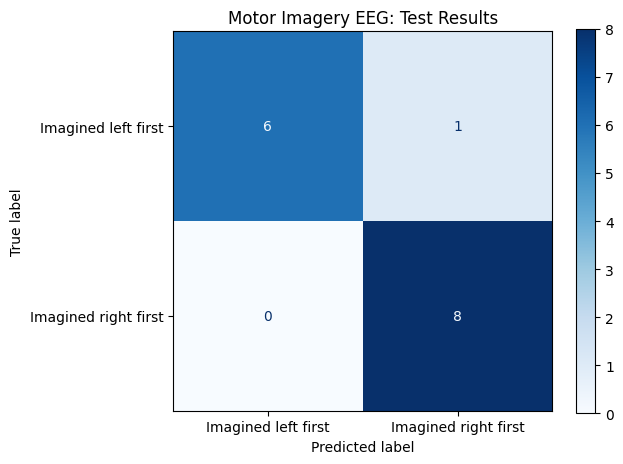

In [9]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=[1, 2],
    display_labels=["Imagined left first", "Imagined right first"],
    cmap="Blues"
)

plt.title("Motor Imagery EEG: Test Results")
plt.tight_layout()
plt.show()

In [10]:
summary = pd.DataFrame([{
    "Subject": subject,
    "Training runs": "4, 8",
    "Test run": 12,
    "Training trials": len(y_train),
    "Test trials": len(y_test),
    "Accuracy": accuracy,
    "Balanced accuracy": balanced_accuracy
}])

summary.to_csv("/content/day2_results.csv", index=False)

print(summary.round(3))
print("Saved: /content/day2_results.csv")

   Subject Training runs  Test run  Training trials  Test trials  Accuracy  \
0        1          4, 8        12               30           15     0.933   

   Balanced accuracy  
0              0.929  
Saved: /content/day2_results.csv


Results and graphs

Legal analysis

Limitations and conclusion

References